# **Klasifikasi Jenis Tanaman Berdasarkan Daun**

Anggota :
1.   Gladys Abel Veneta George (235150201111038)
2.   Aulia Kartika Putri (235150207111033)



In [ ]:
# Download dataset dari GitHub
!wget -O dataset.zip \
https://github.com/Auliakartika150/Dataset_ProjectAkhir/releases/download/v1.0/Dataset.Proyek.Akhir-20251201T103522Z-1-001.zip

# Ekstrak dataset ZIP ke folder 'dataset'
!unzip -q dataset.zip -d dataset/

print("Dataset berhasil diunduh dan diekstrak!")


--2025-12-05 03:45:59--  https://github.com/Auliakartika150/Dataset_ProjectAkhir/releases/download/v1.0/Dataset.Proyek.Akhir-20251201T103522Z-1-001.zip
Resolving github.com (github.com)... 140.82.113.3
Connecting to github.com (github.com)|140.82.113.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/1107580270/e43c49c7-e871-4469-af0b-34c0a6836290?sp=r&sv=2018-11-09&sr=b&spr=https&se=2025-12-05T04%3A35%3A49Z&rscd=attachment%3B+filename%3DDataset.Proyek.Akhir-20251201T103522Z-1-001.zip&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2025-12-05T03%3A35%3A46Z&ske=2025-12-05T04%3A35%3A49Z&sks=b&skv=2018-11-09&sig=c3bkK42iWxuuWsfG3sluOKnmzRXvH0d1zUfSd36VIlE%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MT

In [ ]:
# Import Library
import os
import cv2
import numpy as np
import random
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from skimage.feature import graycomatrix, graycoprops
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [ ]:
# Path dataset
train_path = "/content/dataset/Dataset Proyek Akhir/Train"
test_path  = "/content/dataset/Dataset Proyek Akhir/Test"

In [ ]:
# Fungsi segmentasi daun
def segment_leaf(img):

    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    lower_green = np.array([20, 40, 40])
    upper_green = np.array([90, 255, 255])
    mask_hsv = cv2.inRange(hsv, lower_green, upper_green)

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5,5), 0)
    _, mask_otsu = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask_otsu = cv2.bitwise_not(mask_otsu)
    mask = mask_hsv.copy()

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5,5))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

    segmented = cv2.bitwise_and(img, img, mask=mask)
    return segmented, mask

In [ ]:
# Fungsi ekstraksi fitur
def extract_features(img, mask):
    out = []

    # Warna
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(hsv)
    out.append(cv2.mean(h, mask=mask)[0])
    out.append(cv2.mean(s, mask=mask)[0])
    out.append(cv2.mean(v, mask=mask)[0])

    # Tekstur
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray_masked = cv2.bitwise_and(gray, gray, mask=mask)
    glcm = graycomatrix(gray_masked,
                         distances=[1],
                         angles=[0],
                         levels=256,
                         symmetric=True,
                         normed=True)
    contrast = graycoprops(glcm, 'contrast')[0, 0]
    dissimilarity = graycoprops(glcm, 'dissimilarity')[0, 0]
    homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
    energy = graycoprops(glcm, 'energy')[0, 0]
    correlation = graycoprops(glcm, 'correlation')[0, 0]
    asm = graycoprops(glcm, 'ASM')[0, 0]

    out.extend([contrast, dissimilarity, homogeneity, energy, correlation, asm])

    # Bentuk
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if contours:
        c = max(contours, key=cv2.contourArea)
        area = cv2.contourArea(c)
        peri = cv2.arcLength(c, True)

        x, y, w, h = cv2.boundingRect(c)
        ratio = w / h if h != 0 else 0
        extent = area / (w * h) if w*h != 0 else 0

        hull = cv2.convexHull(c)
        hull_area = cv2.contourArea(hull)
        solidity = area / hull_area if hull_area != 0 else 0

        hu = cv2.HuMoments(cv2.moments(c)).flatten()

        out.extend([area, peri, ratio, extent, solidity])
        out.extend(hu.tolist())

    else:
        out.extend([0] * 12)

    return out

In [ ]:
# Load Data

def load_data(folder_path, sample, show = True):
    X, y = [], []
    visualized = False

    for cls in os.listdir(folder_path):
        class_folder = os.path.join(folder_path, cls)
        if not os.path.isdir(class_folder):
            continue

        images = os.listdir(class_folder)
        sample_images = random.sample(images, min(sample, len(images)))

        for img_name in images:
            img_path = os.path.join(class_folder, img_name)
            img = cv2.imread(img_path)
            if img is None:
                continue

            img = cv2.resize(img, (300, 300))
            leaf, mask = segment_leaf(img)
            features = extract_features(leaf, mask)

            X.append(features)
            y.append(cls)


        for img_name in sample_images:
            img_path = os.path.join(class_folder, img_name)
            img = cv2.imread(img_path)
            img = cv2.resize(img, (300, 300))

            leaf, mask = segment_leaf(img)

            plt.figure(figsize=(8,4))

            plt.subplot(1,4,1)
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            plt.title(f"Asli ({cls})")
            plt.axis("off")

            plt.subplot(1,4,2)
            plt.imshow(mask, cmap="gray")
            plt.title("Mask")
            plt.axis("off")

            plt.subplot(1,4,3)
            plt.imshow(cv2.cvtColor(leaf, cv2.COLOR_BGR2RGB))
            plt.title("Daun")
            plt.axis("off")

            cont = img.copy()
            conts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            if conts:
                cv2.drawContours(cont, conts, -1, (0,255,0), 2)

            plt.subplot(1,4,4)
            plt.imshow(cv2.cvtColor(cont, cv2.COLOR_BGR2RGB))
            plt.title("Kontur")
            plt.axis("off")

            plt.show()

    return X, y

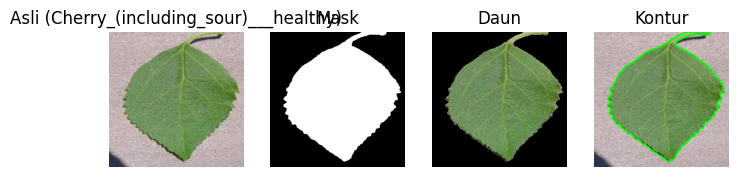

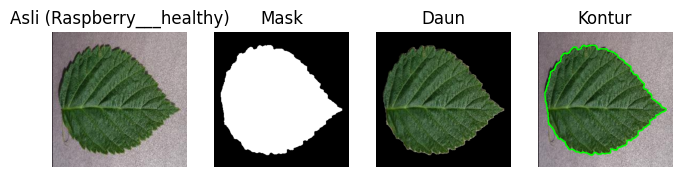

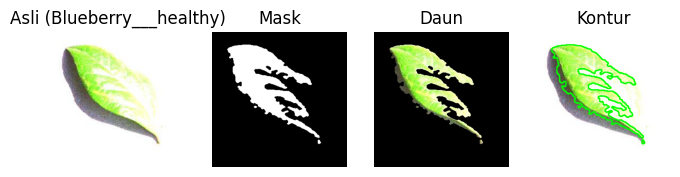

Jumlah data TRAIN: 4087
Jumlah data TEST : 1355


In [ ]:
# Visualisasi Data
X_train, y_train = load_data(train_path, sample = 1, show = True)
X_test, y_test = load_data(test_path, sample = 0, show = False)

print("Jumlah data TRAIN:", len(X_train))
print("Jumlah data TEST :", len(X_test))

In [ ]:
# Normalisasi
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

In [ ]:
# Model SVM
svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True)
svm_model.fit(X_train_scaled, y_train)

print("Model SVM selesai dilatih!")

Model SVM selesai dilatih!



Akurasi Test : 0.9712

=== CLASSIFICATION REPORT ===
                                   precision    recall  f1-score   support

              Blueberry___healthy       0.97      0.98      0.98       454
Cherry_(including_sour)___healthy       0.95      0.99      0.97       456
              Raspberry___healthy       0.99      0.94      0.96       445

                         accuracy                           0.97      1355
                        macro avg       0.97      0.97      0.97      1355
                     weighted avg       0.97      0.97      0.97      1355



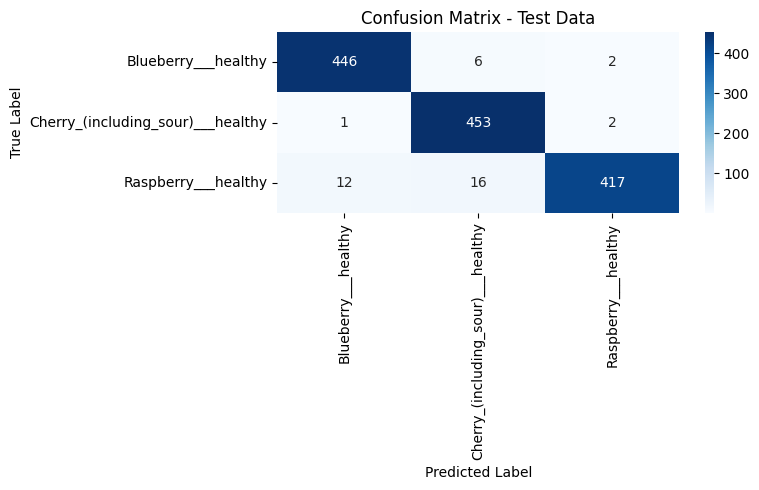


=== CONFUSION MATRIX ===
[[446   6   2]
 [  1 453   2]
 [ 12  16 417]]


In [ ]:
# Validasi Data


y_test_pred = svm_model.predict(X_test_scaled)
acc = accuracy_score(y_test, y_test_pred)
print(f"\nAkurasi Test : {acc:.4f}")

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_test_pred, zero_division=0))
unique_labels = np.unique(y_test)
cm_valid = confusion_matrix(y_test, y_test_pred, labels=unique_labels)

plt.figure(figsize=(8, 5))
sns.heatmap(
    cm_valid,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=unique_labels,
    yticklabels=unique_labels
)
plt.title("Confusion Matrix - Test Data")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

print("\n=== CONFUSION MATRIX ===")
print(cm_valid)